# AdaBoost

**Review 2 - Classification Part B - target: transmission**

Predict Automatic vs Manual using 2,500 balanced UK listing records. The fixed 80:20
stratified split gives 2,000 training rows and 500 held-out test rows. Selection uses
five-fold training macro F1; the test set never chooses parameters. Preprocessing is fitted
inside each fold, and before/after tuning results use the same features and split.

## 1. Imports

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook inside the project or project/notebooks folder.")
sys.path.insert(0, str(ROOT))

from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.model_selection import GridSearchCV, cross_validate
import joblib

from src.classification import *


## 2. Dataset audit, target definition and preprocessing

In [2]:
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]

display(
    pd.DataFrame(
        {
            "Raw": raw[TARGET].value_counts(),
            "Cleaned": df[TARGET].value_counts(),
            "Train": y_train.value_counts(),
            "Test": y_test.value_counts(),
        }
    )
)
display(df.dtypes.to_frame("dtype").astype(str))
print("Raw shape:", raw.shape)
print("Cleaned shape:", df.shape)
print("Removed exact duplicate rows:", len(raw) - len(df))
print("Training rows:", len(train), "| Held-out test rows:", len(test))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)


Raw shape: (2500, 10)
Cleaned shape: (2500, 10)
Removed exact duplicate rows: 0
Training rows: 2000 | Held-out test rows: 500


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


## 3. Required EDA

Cleaned shape: (2500, 10) | Training: 2000 | Test: 500
Missing training values:
 brand            0
model            0
year             0
price_gbp        0
mileage_miles    0
fuel_type        0
tax_gbp          0
mpg_uk           0
engine_size_l    0
transmission     0
Training IQR outlier counts (retained; log transforms reduce skew):
car_age           38
log_price         22
log_mileage       74
tax_gbp          642
mpg_uk            20
engine_size_l    147


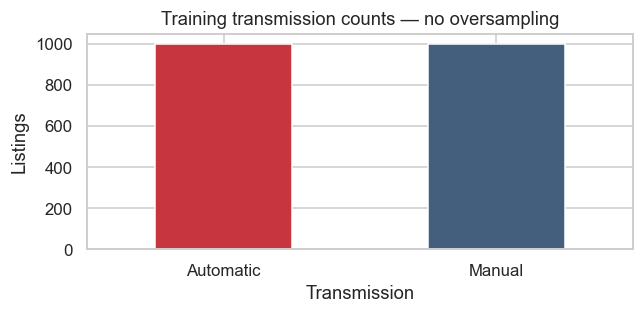

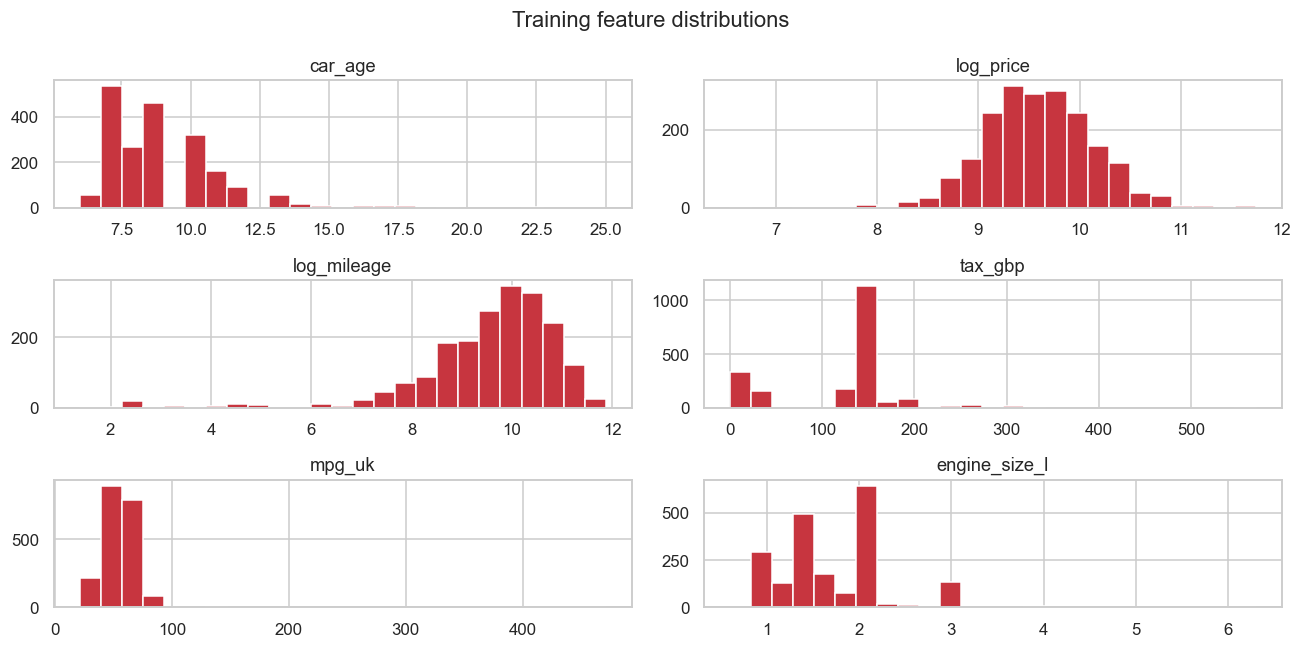

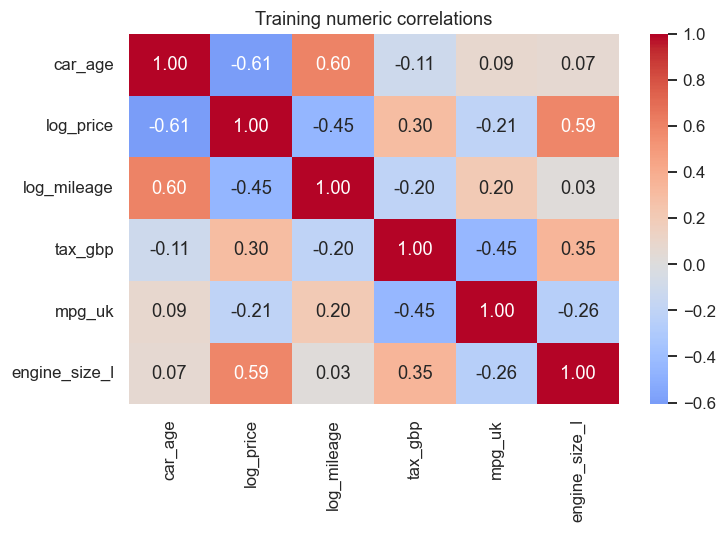

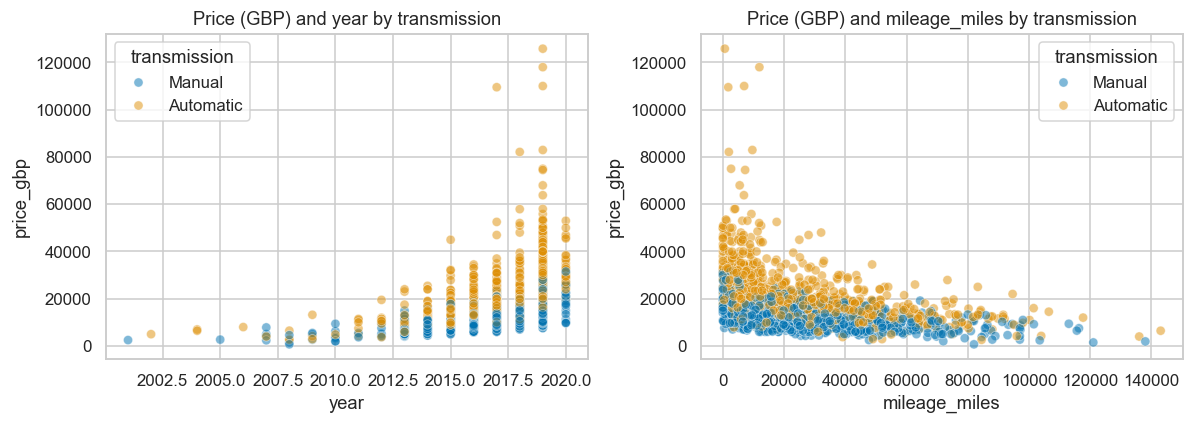

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,2000,9,Ford,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,2000,143,Fiesta,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2000.0,NaN,NaN,NaN,2016.9735,2.129569,2001.0,2016.0,2017.0,2019.0,2020.0
price_gbp,2000.0,NaN,NaN,NaN,17001.7955,10392.673128,694.0,10417.25,14492.0,20900.0,125796.0
mileage_miles,2000.0,NaN,NaN,NaN,24529.251,21740.610165,3.0,8121.75,18820.0,34000.0,143000.0
fuel_type,2000,4,Petrol,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax_gbp,2000.0,NaN,NaN,NaN,120.4075,67.327468,0.0,125.0,145.0,145.0,570.0
mpg_uk,2000.0,NaN,NaN,NaN,55.725,17.138348,21.4,46.3,55.4,63.15,470.8
engine_size_l,2000.0,NaN,NaN,NaN,1.7235,0.577472,0.6,1.4,1.6,2.0,6.3
transmission,2000,2,Manual,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


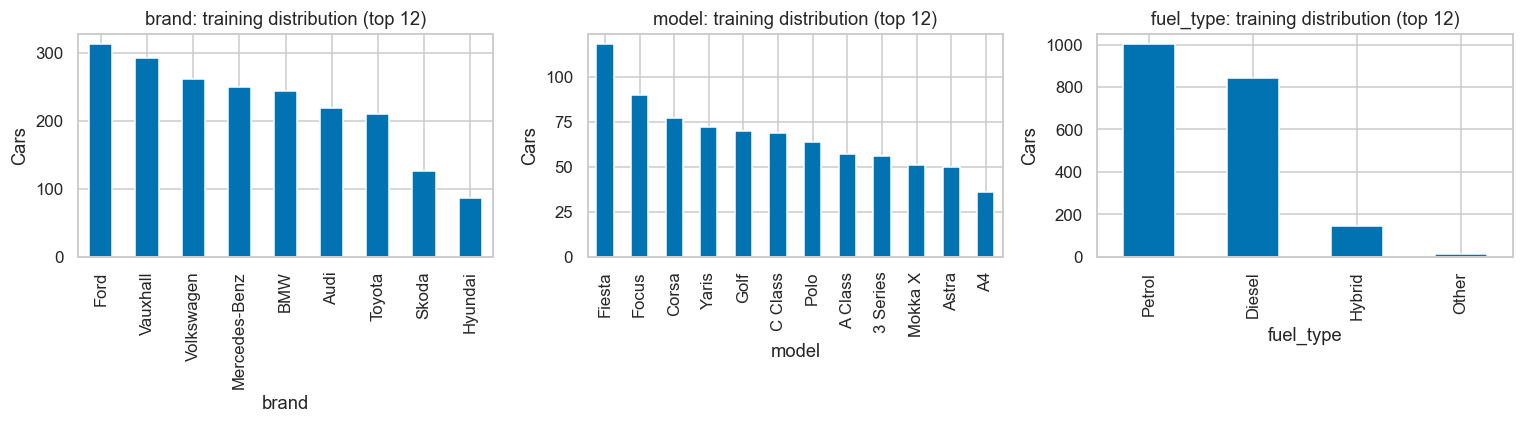

In [3]:
audit_plots(df, train)
display(train.describe(include="all").T)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
engineered_train = CarFeatures().transform(X_train)
for axis, column in zip(axes.ravel(), ["brand", "model", "fuel_type"]):
    engineered_train[column].value_counts().head(12).plot.bar(ax=axis)
    axis.set(
        title=f"{column}: training distribution (top 12)",
        xlabel=column,
        ylabel="Cars",
    )
plt.tight_layout()
plt.show()


## 4. Model training and tuning

The first cell evaluates the untuned baseline. The second uses GridSearchCV; the search includes the baseline settings, and lower held-out performance is reported honestly.

In [4]:
slug = "adaboost"
name, estimator, parameter_grid = configurations()[slug]
print("Baseline estimator:")
display(estimator)
print("Parameter grid:")
display(parameter_grid)

baseline = build_pipeline(clone(estimator))
warning_messages = []
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")
    baseline_cv = cross_validate(
        baseline,
        X_train,
        y_train,
        cv=CV,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    baseline.fit(X_train, y_train)

warning_messages.extend(str(item.message) for item in captured)
display(
    pd.DataFrame(
        {key: value for key, value in baseline_cv.items() if key.startswith("test_")}
    )
)
print("Mean baseline CV macro F1:", baseline_cv["test_f1_macro"].mean())

Baseline estimator:
Parameter grid:
Mean baseline CV macro F1: 0.8051795009719773


,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


[{'model__n_estimators': [50], 'model__learning_rate': [1.0]},
 {'model__n_estimators': [100, 200], 'model__learning_rate': [0.1, 0.5]}]

,test_f1_macro,test_f1_weighted,test_balanced_accuracy
0,0.819995,0.819995,0.8200
1,0.819982,0.819982,0.8200
2,0.756549,0.756549,0.7575
3,0.802053,0.802053,0.8025
4,0.827318,0.827318,0.8275


In [5]:
search = GridSearchCV(
    build_pipeline(clone(estimator)),
    parameter_grid,
    scoring=SCORING,
    refit="f1_macro",
    cv=CV,
    n_jobs=1,
    error_score="raise",
    return_train_score=False,
)
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")
    search.fit(X_train, y_train)

warning_messages.extend(str(item.message) for item in captured)
tuned = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best training CV macro F1:", search.best_score_)
display(
    pd.DataFrame(search.cv_results_)[
        [
            "params",
            "mean_test_f1_macro",
            "std_test_f1_macro",
            "mean_test_f1_weighted",
            "rank_test_f1_macro",
        ]
    ].sort_values("rank_test_f1_macro")
)
print("Recorded training warnings:", sorted(set(warning_messages)) or "None")

Best parameters: {'model__learning_rate': 0.1, 'model__n_estimators': 200}
Best training CV macro F1: 0.8098501100896813
Recorded training warnings: None


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_f1_weighted,rank_test_f1_macro
2,"{'model__learning_rate': 0.1, 'model__n_estima...",0.809850,0.025749,0.809850,1
4,"{'model__learning_rate': 0.5, 'model__n_estima...",0.808686,0.028614,0.808686,2
1,"{'model__learning_rate': 0.1, 'model__n_estima...",0.806794,0.027485,0.806794,3
0,"{'model__learning_rate': 1.0, 'model__n_estima...",0.805180,0.025704,0.805180,4
3,"{'model__learning_rate': 0.5, 'model__n_estima...",0.800780,0.032544,0.800780,5


## 5. Evaluation

,Model,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,AdaBoost,Before tuning,0.814,0.8155,0.814,0.8138,0.8138,0.814,0.8369,0.780,0.8978,0.9058,0.8052,0.0257
1,AdaBoost,After tuning,0.806,0.8129,0.806,0.8049,0.8049,0.806,0.8592,0.732,0.9005,0.9048,0.8099,0.0257


,After minus before
Accuracy,-0.008
F1_weighted,-0.008853
F1_macro,-0.008853
Automatic_recall,-0.048
ROC_AUC,0.002664
CV_macro_F1,0.004671


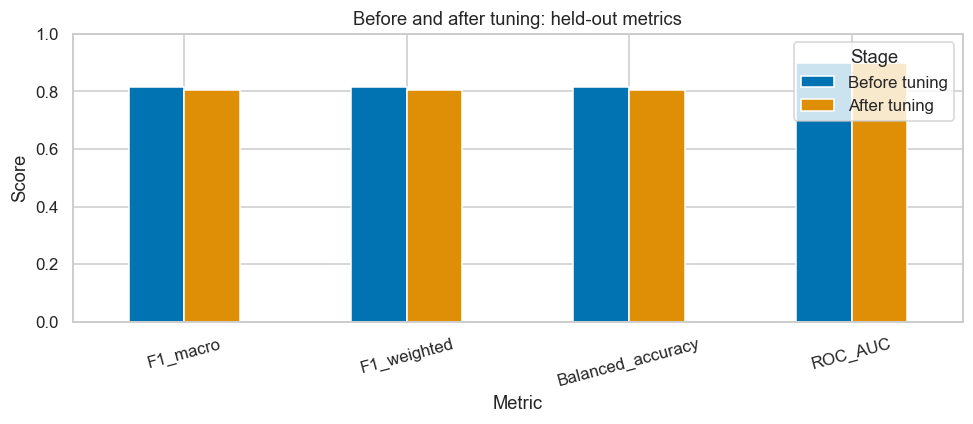

In [6]:
comparison = evaluate_pair(
    slug,
    name,
    baseline,
    tuned,
    X_test,
    y_test,
    baseline_cv,
    search,
    warning_messages,
)
display(comparison.round(4))

metric_columns = [
    "Accuracy",
    "F1_weighted",
    "F1_macro",
    "Automatic_recall",
    "ROC_AUC",
    "CV_macro_F1",
]
delta = comparison.loc[1, metric_columns] - comparison.loc[0, metric_columns]
display(delta.to_frame("After minus before"))

comparison.set_index("Stage")[
    ["F1_macro", "F1_weighted", "Balanced_accuracy", "ROC_AUC"]
].T.plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title("Before and after tuning: held-out metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Confusion matrix and model interpretation

,precision,recall,f1-score,support
Automatic,0.8592,0.732,0.7905,250.000
Manual,0.7666,0.880,0.8194,250.000
accuracy,0.8060,0.806,0.8060,0.806
macro avg,0.8129,0.806,0.8049,500.000
weighted avg,0.8129,0.806,0.8049,500.000


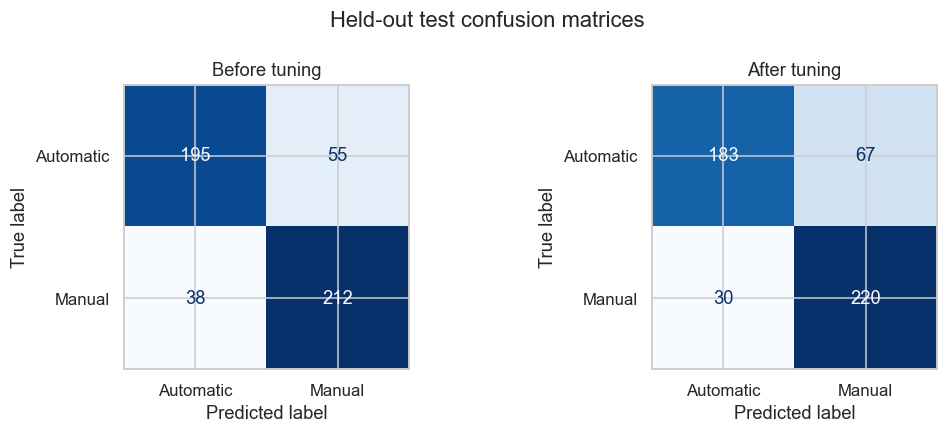

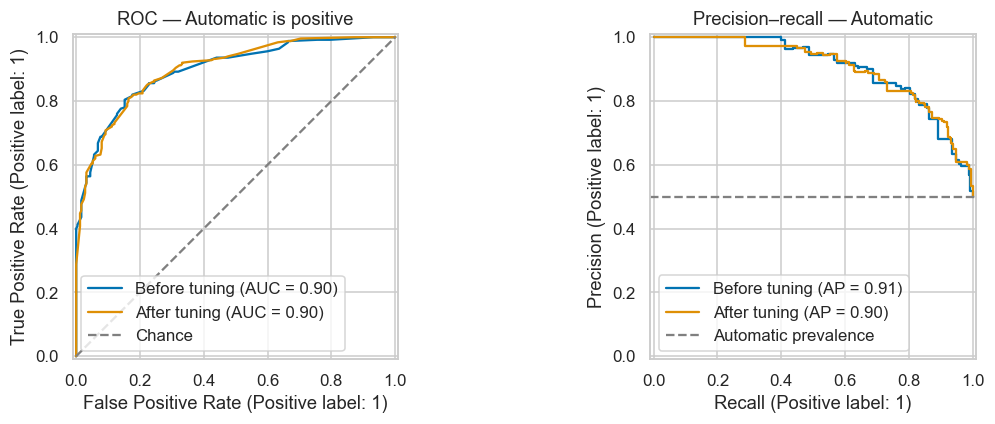

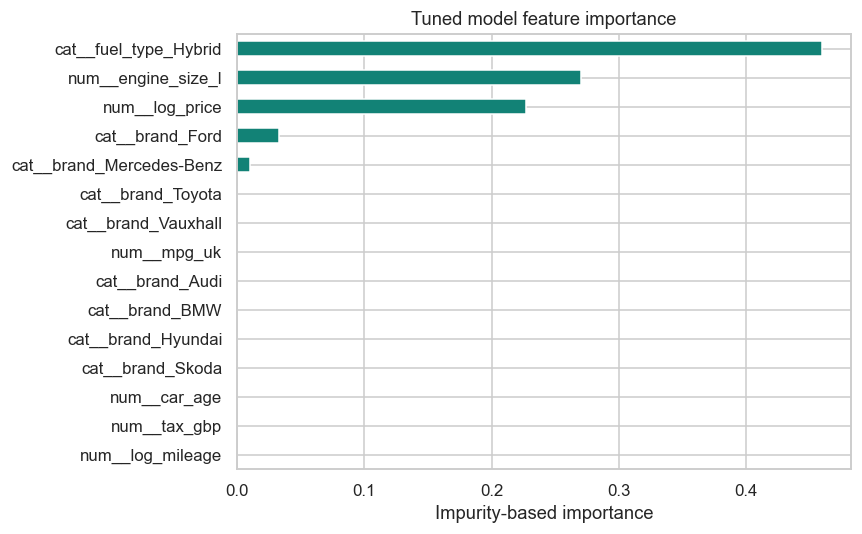

In [7]:
display(
    pd.read_csv(
        ROOT / "results" / slug / "after_class_report.csv", index_col=0
    ).round(4)
)
plot_pair(slug, baseline, tuned, X_test, y_test)

## 7. Observation / Interpretation

**Observation:** This notebook compares the baseline and CV-selected **AdaBoost** classifier on one untouched test split.

- Identify the metric that changed most and report the exact after-minus-before value.
- Compare Automatic-class errors in the two confusion matrices.
- Explain how the selected hyperparameters affect this model's learning mechanism.
- Explain why a CV improvement may not produce a held-out improvement.
- Discuss why oversampling is unnecessary for this balanced dataset.

Models and numeric results are exported to `models/` and `results/`; the GUI reads those same files.
Complete the interpretation using the executed evidence and your own wording.